In [1]:
import cv2
import matplotlib.pyplot as plt
import gymnasium as gym
import stable_baselines3 as sb3

In [2]:
# create the environment
env = gym.make("CartPole-v1", render_mode="rgb_array")
# reset the environment
obs, info = env.reset()
print(obs) # obs: initial observation
print(info) # info: additional information about the environment

[ 0.02238609 -0.00957019  0.01172147  0.03757663]
{}


(400, 600, 3)


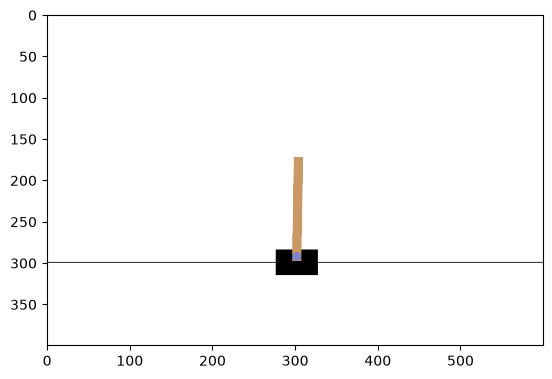

In [3]:
# render the environment at the current state
frame = env.render() # in this case, the render is not the observation
print(frame.shape)
plt.imshow(frame)

In [4]:
# show the observation space and action space of the environment
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Random Observation:", env.observation_space.sample())
print("Random Action:", env.action_space.sample())

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Random Observation: [ 0.39457858 -0.4452311   0.4080457  -0.9481462 ]
Random Action: 0


Observation: [ 0.02219468 -0.20485824  0.012473    0.33393463]
Reward: 1.0
Terminated: False
Truncated: False
Info: {}


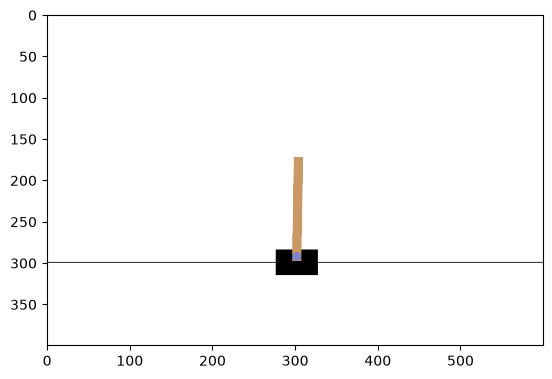

In [5]:
# run a few times to see the pole falling down
obs, reward, terminated, truncated, info = env.step(0) # take action 0 (push cart to the left)
print("Observation:", obs)
print("Reward:", reward)
print("Terminated:", terminated) # true if the episode has ended (win or lose, anyway the episode is over)
# 注意，环境并不会等 Pole 完全倒下才结束，而是当 Pole 倾斜角度超过 12 度或者小车位置超过 2.4 时就会结束
print("Truncated:", truncated) # true if the episode has been truncated (the maximum number of steps has been reached)
print("Info:", info)
plt.imshow(env.render())

In [6]:
# write a function to test model
def test_model(env, model, video=None, msg=None):
    obs, info = env.reset()
    ep_len = 0
    ep_rew = 0
    while True:
        # perform the action, update total reward and length of the episode
        action, _ = model.predict(obs)
        obs, reward, terminated, truncated, info = env.step(action)
        ep_len += 1
        ep_rew += reward
        
        # record frame to the video
        if video:
            frame = env.render()
            frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
            frame = cv2.putText(
                frame, # image
                msg, # text to add
                (10, 25), # bottom-left corner of the text
                cv2.FONT_HERSHEY_SIMPLEX, # font
                1, # font scale
                (0, 0, 0), # color (BGR)
                2, # thickness
                cv2.LINE_AA # line type
            )
            video.write(frame)
        
        if terminated or truncated:
            return ep_len, ep_rew

In [7]:
# write a random model to test the environment
class RandomModel:
    def __init__(self, env):
        self.env = env
    def predict(self, obs):
        return self.env.action_space.sample(), None

In [11]:
FPS = 30
FOURCC = cv2.VideoWriter_fourcc(*"H264")
VIDEO_PATH = "random_model.mp4"
width, height = frame.shape[1], frame.shape[0]
# create a video writer to record the frames
video = cv2.VideoWriter(VIDEO_PATH, FOURCC, FPS, (width, height))
# reset the environment
env.reset()

# test the random model
for ep in range(5):
    ep_len, ep_rew = test_model(env, RandomModel(env), video, msg=f"Random Model, episode:{ep}")
    print(f"Random Model Episode {ep}: length={ep_len}, reward={ep_rew}")
# release the video writer
video.release()

Random Model Episode 0: length=39, reward=39.0
Random Model Episode 1: length=20, reward=20.0
Random Model Episode 2: length=24, reward=24.0
Random Model Episode 3: length=32, reward=32.0
Random Model Episode 4: length=13, reward=13.0


In [ ]:
# train a PPO model in the environment
model = sb3.PPO("MlpPolicy", env, verbose=1)
model.learn(total_timesteps=10_000)
model.save("ppo_cartpole")

In [12]:
VIDEO_PATH = "ppo_model.mp4"
video = cv2.VideoWriter(VIDEO_PATH, FOURCC, FPS, (width, height))
# load the PPO model
model = sb3.PPO.load("ppo_cartpole")

# test the PPO model
for ep in range(5):
    ep_len, ep_rew = test_model(env, model, video, msg=f"PPO Model, episode:{ep}")
    print(f"PPO Model Episode {ep}: length={ep_len}, reward={ep_rew}")
# release the video writer
video.release()

PPO Model Episode 0: length=311, reward=311.0
PPO Model Episode 1: length=74, reward=74.0
PPO Model Episode 2: length=123, reward=123.0
PPO Model Episode 3: length=234, reward=234.0
PPO Model Episode 4: length=153, reward=153.0
